**Ablation: what changes the quantum model's results?**

`Quantum.ipynb` trains one circuit. Here we change one thing at a time and see what happens, using the same 5 splits and the same training code (`vqc.py`):

1. **Depth:** 1, 2, 3 and 4 layers. More layers means more trainable parameters and a more expressive circuit, but also longer training.
2. **Entanglement:** the main circuit vs. the same 3 layers of rotations with the CNOT gates removed. Without two-qubit gates, qubit 0 (the one we measure) never interacts with qubits 1 to 3, so the output can only depend on feature 0 (median income). Any extra accuracy of the entangled model over this one is what entanglement adds here.

Run `Classical.ipynb` and `Quantum.ipynb` first. This notebook takes a few minutes.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import vqc

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEEDS = [0, 1, 2, 3, 4]

CONFIGS = {
    "1 layer": dict(n_layers=1),
    "2 layers": dict(n_layers=2),
    "3 layers (main model)": dict(n_layers=3),
    "4 layers": dict(n_layers=4),
    "3 layers, no entanglement": dict(n_layers=3, entangle=False),
}

In [2]:
ablation = {}
for name, cfg in CONFIGS.items():
    ablation[name] = [vqc.run_seed(seed, **cfg)[0] for seed in SEEDS]
    accs = [r["test_acc"] for r in ablation[name]]
    print(f"{name:28s} params = {ablation[name][0]['n_params']:3d}   test = {np.mean(accs):.3f} ± {np.std(accs, ddof=1):.3f}")

with open(RESULTS / "ablation.json", "w") as f:
    json.dump(ablation, f, indent=2)

1 layer                      params =  12   test = 0.613 ± 0.052
2 layers                     params =  24   test = 0.699 ± 0.017
3 layers (main model)        params =  36   test = 0.790 ± 0.028
4 layers                     params =  48   test = 0.792 ± 0.037
3 layers, no entanglement    params =  36   test = 0.737 ± 0.036


In [3]:
rows = [{"config": name, **r} for name, runs in ablation.items() for r in runs]
df = pd.DataFrame(rows)
abl = df.groupby("config", sort=False).agg(
    n_params=("n_params", "first"),
    test_mean=("test_acc", "mean"), test_std=("test_acc", "std"),
    train_mean=("train_acc", "mean"),
    time_mean_s=("fit_time_s", "mean"),
).round(3)
abl["train_test_gap"] = (abl.train_mean - abl.test_mean).round(3)
abl.to_csv(RESULTS / "ablation_summary.csv")
abl

,n_params,test_mean,test_std,train_mean,time_mean_s,train_test_gap
config,,,,,,
1 layer,12,0.613,0.052,0.601,0.822,-0.012
2 layers,24,0.699,0.017,0.729,1.451,0.030
3 layers (main model),36,0.790,0.028,0.797,2.125,0.007
4 layers,48,0.792,0.037,0.797,2.537,0.005
"3 layers, no entanglement",36,0.737,0.036,0.749,1.520,0.012


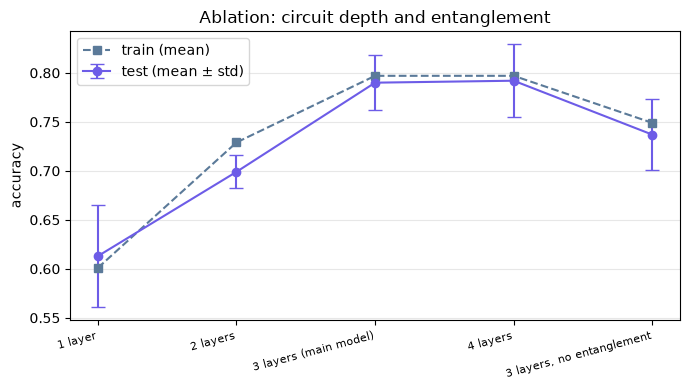

3-layer ablation row matches Quantum.ipynb: True


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(abl))
ax.errorbar(x, abl.test_mean, yerr=abl.test_std, fmt="o-", capsize=5, label="test (mean ± std)", color="#6d5ce7")
ax.plot(x, abl.train_mean, "s--", label="train (mean)", color="#5b7a99")
ax.set_xticks(x); ax.set_xticklabels(abl.index, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("accuracy"); ax.set_title("Ablation: circuit depth and entanglement")
ax.grid(axis="y", alpha=0.3); ax.legend()
plt.tight_layout(); fig.savefig(RESULTS / "ablation.png", dpi=200); plt.show()

# Reproducibility check: the 3-layer row must equal the main run in Quantum.ipynb (up to floating-point noise)
try:
    main = [r["test_acc"] for r in json.load(open(RESULTS / "quantum.json"))["vqc"]]
    same = [r["test_acc"] for r in ablation["3 layers (main model)"]]
    print("3-layer ablation row matches Quantum.ipynb:", np.allclose(main, same))
except FileNotFoundError:
    print("results/quantum.json not found - run Quantum.ipynb first for this check")

## What to look for

- **Depth:** compare the test column with the train column. If train accuracy rises with more layers but test accuracy does not, extra depth is only fitting noise. Also note the cost: every extra layer adds 12 parameters and more simulation time.
- **Entanglement:** the no-entanglement circuit can only see feature 0, so it is a measure of how far one feature alone gets you. The gap between it and the main model is what the CNOT gates buy on this dataset.
- Remember the ±3 point sampling noise on a 200-row test set: only differences clearly larger than that mean anything.